# PETadex.v260701 Creation: 5. Creating the Logan query

> **Author:** Thomas Quigley\
> **Date Started:** August 22nd, 2026\
> **Date Finished:** September 26th, 2026\
> **Input:** \
> s3://petadex/petadex.v260701/4_hmm_creation/petadex_hmms/*.hmm\
> s3://petadex/petadex.v260701/3_msa_cleaning/plasticome.v2.sequence_annotations.csv\
> s3://petadex/petadex.v260701/2_nr_search/petadex-nr.v260701.significant-hits.fastaa\
> **Output:** \
> s3://petadex/petadex.v260701/5_creating_logan_query/petadex-nr.v260701.catalytic_domain_annotations.csv\
> s3://petadex/petadex.v260701/5_creating_logan_query/petadex-nr.v260701.proteins.fastaa\
> s3://petadex/petadex.v260701/5_creating_logan_query/petadex.v260701.logan_query.fastaa
---

## 1. Objective
In order to query into the Logan contigs, I need to send Rayan a fastaa file of sequences I would like to query. Since we want to minimize the cost of the search, we are querying sequences that must have a complete catalytic domain (the catalytic residue sites are not empty) according to the HMMs, and only 90pid centroids (clustering HMM-extracted regions, global). This should remove any too divergent sequences from entering the search, and any off-target accessory domains.

To do this, the following steps will have to be performed:
1. HMMsearch the HMMs into the NCBI nr significant hits (below 1.0E-5) and return which ones have complete catalytic domains, and their ranges.
2. Extract the complete catalytic domains from the NCBI nr significant hits fastaa.
3. Cluster the catalytic domains using diamond.

### 1.1. Place in the Project
---
We now have HMMs that are seeded from the PETadex-Platicome.v260701 dataset and built from the homologs found in the NCBI non-redundant protein database. Now, we want to use these HMMs to subset the NCBI nr homologs to create our Logan query dataset. We want to minimize the number of sequences we search, so we are going to subset based on containing a complete catalytic domain (removes off-target), and taking 90pid centroids (global alignment of hmm-extracted region). 

## 2. Methods
### 2.0. Install requirements
---
- HMMER 3.4 (Aug 2023); http://hmmer.org/
- diamond version 2.2.4
- MMseqs2 Release 18-8cc5c


### 2.0.1. Create component subset fastaas
---
This code block breaks up the significant hits fastaa into individual component fastaas for faster search times (10 hours to about 1 hour).

In [4]:
# ────────────── #
# SCRIPT SET UP  #
# ────────────── #

import os
from collections import Counter

# ─── INPUT  ─── #
NR_HITS = "../s3/2_nr_search/petadex-nr.v260701.significant-hits.fastaa"
"""
>WP_305403363.1|7.24e-11|23.5|73.6|PL181|C034 # last field of the header is component_id by rsplit("|", 6)
"""
PLASTICOME = "../s3/petadex-plasticome.v260701.proteins.fastaa"
"""
PL1|WP_054022242.1|A0A0K8P6T7.1:6QGC_A:6QGC_B:6QGC_C:6QGC_D:WLY76725.1:MFG5410765.1:MHF3933096.1:YDX79718.1:GAP38373.1|1|C001 # last field is component_id
"""

# ─── OUTPUT  ─── #
TARGET_FASTAAS = "./5_creating_logan_query/per_component_fastaas" # /petadex-nr.significant-hits.{component_id}.fa

os.makedirs(TARGET_FASTAAS, exist_ok=True)

# ───────────────────────────── #
# SPLIT FASTAA BY COMPONENT_ID  #
# ───────────────────────────── #

# ─── READ AND PARSE INPUT FASTAA  ─── #

component_counts = Counter()
plasticome_counts = Counter()
component_handles = {}

def get_component_handle(component_id):
    handle = component_handles.get(component_id)
    if handle is None:
        handle = open(os.path.join(TARGET_FASTAAS, f"petadex-nr.significant-hits.{component_id}.fa"), "w")
        component_handles[component_id] = handle
    return handle

current_component_id = None
try:
    with open(NR_HITS) as infile:
        for line in infile:
            if line.startswith(">"):
                accession, e_value, pid, bitscore, query_petadex_id, current_component_id = line[1:].strip().rsplit("|", 5) # accession may itself contain "|", so split from the right
                component_counts[current_component_id] += 1

            get_component_handle(current_component_id).write(line)

    # ─── APPEND THE PLASTICOME SEQUENCES TO THE SAME PER-COMPONENT FASTAAS ─── #
    with open(PLASTICOME) as infile:
        for line in infile:
            if line.startswith(">"):
                current_component_id = line[1:].strip().rsplit("|", 1)[-1] # component_id is always the last field
                plasticome_counts[current_component_id] += 1

            get_component_handle(current_component_id).write(line)
finally:
    for handle in component_handles.values():
        handle.close()

# ─── OUTPUT COMPONENT FASTAAS  ─── #
print(f"{len(component_handles)} component fastaas written -> {TARGET_FASTAAS}/")
print()
print(f"{'component':<10}{'nr_sequences':>14}{'plasticome_sequences':>22}")
for component_id in sorted(set(component_counts) | set(plasticome_counts)):
    print(f"{component_id:<10}{component_counts[component_id]:>14,}{plasticome_counts[component_id]:>22,}")
print(f"{'total':<10}{sum(component_counts.values()):>14,}{sum(plasticome_counts.values()):>22,}")

46 component fastaas written -> ./5_creating_logan_query/per_component_fastaas/

component   nr_sequences  plasticome_sequences
C001             653,033                   291
C002              28,185                    18
C003             905,480                    25
C004             106,621                     2
C005              67,772                    48
C006              40,890                     5
C007             372,764                     4
C008               6,760                     5
C009               7,873                     2
C010               2,637                     1
C011               9,627                     3
C012              28,286                     5
C013               7,048                     1
C014             891,449                    15
C015             294,501                     2
C016             923,564                     1
C017             542,718                     1
C018              22,719                     7
C019              44,697  

### 2.1. Obtain all NCBI nr hits that contain an HMM hit
---
This section will search the PETadex-HMMs against the NCBI nr homologs obtained in 2_nr_search. This will produce the following information:
1. Which sequences have an HMM hit below the e-value cutoff. No fastaa of these sequences is written out -- the annotations csv below carries enough (petadex_id, component_id) to look up each hit's sequence in the per-component database fastas already built in section 2.0.1.
2. The range where the HMM hit to. The hmm_start and hmm_end values will be columns in a csv called "petadex-nr.v260701.catalytic_domain_annotations.csv".
3. The identity of the amino acids in the catalytic residue of the HMM-hit sequences. The identity and amino acid position will be columns in "petadex-nr.v260701.catalytic_domain_annotations.csv".
4. If the sequence is a complete (contains a residue in all catalytic positions) or partial (not all the catalytic sites were aligned to). This will be held as a boolean in the table "petadex-nr.v260701.catalytic_domain_annotations.csv".

The pipeline of the following scripts is the following:
1. HMMalign the annotations to the HMMs
2. HMMsearch the HMMs against their component fastaas
3. Parse the results to output all sequences with a hit below the e-value cutoff.
4. For each significant hit, output the annotations for the sequence (information mentioned above).

In [1]:
%%bash

# ────────────────────── #
# HMMSEARCH THE NR HITS  #
# ────────────────────── #
MASTER_DIRECTORY="./5_creating_logan_query/hmm_search"

# ─── INPUT  ─── #
TARGET_FASTAAS="./5_creating_logan_query/per_component_fastaas"
# nr header format:
# >genbank_accessions|e-value|pid|bitscore|query_petadex_id|component_id 
# ex.
# >KAG5547207.1|8.21e-13|26.9|81.3|PL40|C001
# 
# plasticome header format:
# >petadex_id|primary_genbank_accession|genbank_accessions|pazy_ids|component_id
# ex. 
# >PL1|WP_054022242.1|A0A0K8P6T7.1:6QGC_A:6QGC_B:6QGC_C:6QGC_D:WLY76725.1:MFG5410765.1:MHF3933096.1:YDX79718.1:GAP38373.1|1|C001

PLASTICOME_HMMS="../s3/4_hmm_creation/petadex_hmms" # file format petadex.v260701-{sub_component_id}.hmm
ANNOTATIONS="../s3/3_msa_cleaning/plasticome.v2.sequence_annotations.csv"

# ─── OUTPUT  ─── #
PETADEX_PLASTICOME_NR_HMM_ANNOTATIONS="../s3/5_creating_logan_query/petadex-nr.v260701.catalytic_domain_annotations.csv" # every hit below e-value cutoff, no dedup
# column format:
# petadex_id,component_id,hmm_name,hmm_evalue,hmm_target_start,hmm_target_end,complete_catalytic_hit,catalytic_site_identities
# ex.
# KAG5547207.1:KAI8553478.1,C001,C001-1.hmm,3.21e-19,2,150,TRUE,S130(S165):D183(E203):H213(H290)
# an accession/id can appear on multiple rows if it has multiple significant hits; complete_catalytic_hit is TRUE or FALSE per-hit
# no fastaa is written out -- resolve a hit's sequence from per_component_fastaas/petadex-nr.significant-hits.{component_id}.fa (see section 2.2)

# ─── SCRIPTS  ─── #
SEARCH_SCRIPT="../s3/5_creating_logan_query/scripts/hmmsearch-260823.sh"
TRANSFER_SCRIPT="../s3/5_creating_logan_query/scripts/hmmsearch-260823.transfer_annotations.py"
PARSE_SCRIPT="../s3/5_creating_logan_query/scripts/hmmsearch-260823.parse_output.py"

# ─── PARAMETERS  ─── #
NCBI_SIZE=1101054423

# ─── RUN SCRIPT  ─── #
bash "${SEARCH_SCRIPT}" \
  --transfer-script "${TRANSFER_SCRIPT}" \
  --parse-script "${PARSE_SCRIPT}" \
  --master-directory "${MASTER_DIRECTORY}" \
  --input-hmms-path "${PLASTICOME_HMMS}" \
  --component-database-directory "${TARGET_FASTAAS}" \
  --total-search-size "${NCBI_SIZE}" \
  --reference-annotations "${ANNOTATIONS}" \
  --output-annotations-csv "${PETADEX_PLASTICOME_NR_HMM_ANNOTATIONS}"


2026-09-14 02:52:58 # =========================================== #
2026-09-14 02:52:58 Mon Sep 14 02:52:58 AM UTC 2026 Building shared reference fasta from ../s3/3_msa_cleaning/plasticome.v2.sequence_annotations.csv
2026-09-14 02:52:58 # =========================================== #
2026-09-14 02:52:59 # =========================================== #
2026-09-14 02:52:59 Mon Sep 14 02:52:59 AM UTC 2026 Starting final HMM search
2026-09-14 02:52:59 # =========================================== #
2026-09-14 03:42:10 all 53 job(s) completed successfully
2026-09-14 03:42:10 # =========================================== #
2026-09-14 03:42:10 Mon Sep 14 03:42:10 AM UTC 2026 Reducing across sub-components and writing final outputs
2026-09-14 03:42:10 # =========================================== #


[finalize] Reading every sub-component's hits...
[finalize] 9468263 domain-hit rows across 7562453 unique accessions retained (no dedup, no catalytic-completeness filter)
[finalize] Writing ../s3/5_creating_logan_query/petadex-nr.v260701.catalytic_domain_annotations.csv...
[finalize] Writing /watson/rnalab/tquigley/petadex.v260701/dataset_generation/5_creating_logan_query/hmm_search/summary.csv...
[finalize] Done.


2026-09-14 03:43:52 # =========================================== #
2026-09-14 03:43:52 Mon Sep 14 03:43:52 AM UTC 2026 All HMMs searched! Output: ../s3/5_creating_logan_query/petadex-nr.v260701.catalytic_domain_annotations.csv
2026-09-14 03:43:52 # =========================================== #


### 2.2. Extract the catalytic domains from the HMM hit sequences from nr
---
This code block will read the catalytic domain annotations csv and the per-component database fastas (built in section 2.0.1) to create a pre-clustering Logan query fastaa by:
1. Removing hits that are annotated as FALSE for complete HMM hit
2. Looking up each remaining hit's full sequence in its component's database fasta and extracting only the amino acid sequence from the HMM start to the HMM end

In [2]:
# ───────────── #
# SCRIPT SET UP #
# ───────────── #

import os
import re
import csv
from collections import Counter, defaultdict

# ─── INPUT ─── #
PETADEX_PLASTICOME_NR_HMM_ANNOTATIONS = "../s3/5_creating_logan_query/petadex-nr.v260701.catalytic_domain_annotations.csv"
"""
column format:
petadex_id,component_id,hmm_name,hmm_evalue,hmm_target_start,hmm_target_end,complete_catalytic_hit,catalytic_site_identities
ex.
KAG5547207.1:KAI8553478.1,C001,C001-1.hmm,3.21e-19,2,150,TRUE,S130(S165):D183(E203):H213(H290)
an accession/id can appear on multiple rows if it has multiple significant hits
"""

COMPONENT_DATABASE_DIRECTORY = "./5_creating_logan_query/per_component_fastaas" # petadex-nr.significant-hits.{component_id}.fa
"""
Built in section 2.0.1 -- holds both NR hits and plasticome records for that
component (plasticome records are unconditionally appended there), so it's
the only source of sequences this cell needs. Header formats:
>genbank_accessions|e-value|pid|bitscore|query_petadex_id|component_id
>petadex_id|primary_genbank_accession|genbank_accessions|pazy_ids|component_id (plasticome)
"""

# ─── OUTPUT ─── #
NON_REDUNDANT_PETADEX_NR_PROTEINS = "../s3/5_creating_logan_query/petadex-nr.v260701.proteins.fastaa"
"""
One record per unique NR accession -- its single lowest-hmm_evalue hit across
every sub-component/domain that hit it, given a freshly minted "NR{int}" id.
Plasticome accessions are excluded (they already have their own canonical
fastaa record) even though they go through the same winner-selection below.
header format:
>petadex_id|genbank_accessions|diamond_e-value|diamond_pid|diamond_bitscore|diamond_query_petadex_id|component_id|hmm_evalue|hmm_target_start|hmm_target_end|hmm_name|complete_catalytic_hit
ex.
>NR1|KAG5547207.1:KAI8553478.1|8.21e-13|26.9|81.3|PL40|C001|3.21e-19|2|150|C001-1.hmm|TRUE
"""

PRECLUSTER_QUERY_DIRECTORY = "./5_creating_logan_query/precluster_per_component" # petadex-nr.v260701.precluster_logan_query.{component_id}.fastaa
"""
header format:
>petadex_id|hmm_target_start|hmm_target_end|component_id
ex.
>NR1|2|150|C003
"""

os.makedirs(PRECLUSTER_QUERY_DIRECTORY, exist_ok=True)

EVALUE_CUTOFF = 1.0e-5 # matches the significant-hits cutoff already applied upstream

PLASTICOME_ID_RE = re.compile(r"^PL\d+$")
PLASTICOME_HEADER_RE = re.compile(r"^PL\d+\|")

def is_plasticome_id(petadex_id):
    return bool(PLASTICOME_ID_RE.match(petadex_id))

def record_identity(header):
    """
    Derives the same identity used as petadex_id in the annotations csv (see
    parse_output.py's parse_original_header / is_plasticome_record): an
    existing PL{int} id for plasticome records, or the comma-joined
    genbank_accessions (rewritten colon-joined) for NR records.
    """
    if PLASTICOME_HEADER_RE.match(header):
        return header.split("|", 1)[0]
    genbank_accessions = header.rsplit("|", 5)[0] # accession may itself contain "|", so split from the right
    return genbank_accessions.replace(",", ":")

def parse_original_header(header):
    """
    Parses a per-component database fasta header (NR records only -- see
    is_plasticome_record) back into its fields, mirroring parse_output.py's
    parse_original_header: genbank_accessions|e_value|pid|bitscore|query_petadex_id|component_id.
    """
    genbank_accessions, e_value, pid, bitscore, query_petadex_id, component_id = header.rsplit("|", 5)
    return genbank_accessions, e_value, pid, bitscore, query_petadex_id, component_id

def load_component_records(component_id):
    """identity -> (raw_header, sequence), for every record in this component's database fasta."""
    path = os.path.join(COMPONENT_DATABASE_DIRECTORY, f"petadex-nr.significant-hits.{component_id}.fa")
    records = {}
    header = None
    seq_chunks = []

    def flush():
        if header is not None:
            records[record_identity(header)] = (header, "".join(seq_chunks))

    with open(path) as infile:
        for line in infile:
            line = line.rstrip("\n")
            if line.startswith(">"):
                flush()
                header = line[1:]
                seq_chunks = []
            else:
                seq_chunks.append(line)
    flush()
    return records

nr_counts = Counter()
plasticome_counts = Counter()
component_handles = {}

def get_precluster_handle(component_id):
    handle = component_handles.get(component_id)
    if handle is None:
        handle = open(os.path.join(PRECLUSTER_QUERY_DIRECTORY, f"petadex-nr.v260701.precluster_logan_query.{component_id}.fastaa"), "w")
        component_handles[component_id] = handle
    return handle

def write_domain(component_id, petadex_id, hmm_target_start, hmm_target_end, sequence):
    domain_seq = sequence[hmm_target_start - 1:hmm_target_end] # 1-based inclusive envelope coordinates
    handle = get_precluster_handle(component_id)
    handle.write(f">{petadex_id}|{hmm_target_start}|{hmm_target_end}|{component_id}\n{domain_seq}\n")

# ──────────────────────────────────────────────────────────────── #
# STEP 1: REDUCE TO THE SINGLE LOWEST-HMM_EVALUE HIT PER ACCESSION #
# ──────────────────────────────────────────────────────────────── #

total_rows = 0
winners = {} # petadex_id (original, pre-NR-id) -> winning annotations-csv row
with open(PETADEX_PLASTICOME_NR_HMM_ANNOTATIONS) as infile:
    for row in csv.DictReader(infile):
        total_rows += 1
        hmm_evalue = float(row["hmm_evalue"])
        if hmm_evalue >= EVALUE_CUTOFF:
            continue
        current = winners.get(row["petadex_id"])
        if current is None or hmm_evalue < float(current["hmm_evalue"]):
            winners[row["petadex_id"]] = row

print(f"{total_rows:,} total hit rows reduced to {len(winners):,} accession(s) (single lowest-hmm_evalue hit each)")

# ─────────────────────────────────────────────────────────────────── #
# STEP 2: ASSIGN FRESH NR{int} IDS AND WRITE THE NON-REDUNDANT FASTAA #
# ─────────────────────────────────────────────────────────────────── #

nr_original_ids = sorted(pid for pid in winners if not is_plasticome_id(pid))
new_ids = {original_id: f"NR{i}" for i, original_id in enumerate(nr_original_ids, start=1)}

by_component = defaultdict(list) # component_id -> [(original_petadex_id, row), ...]
for original_id, row in winners.items():
    by_component[row["component_id"]].append((original_id, row))

resolved = {} # final_petadex_id -> (component_id, hmm_target_start, hmm_target_end, complete_catalytic_hit, sequence)

with open(NON_REDUNDANT_PETADEX_NR_PROTEINS, "w") as fasta_out:
    for component_id, entries in sorted(by_component.items()):
        records = load_component_records(component_id)

        for original_id, row in sorted(entries, key=lambda e: e[0]):
            record = records.get(original_id)
            if record is None:
                print(f"WARNING: '{original_id}' not found in component {component_id}'s database fasta — skipping")
                continue
            header, sequence = record
            hmm_target_start = int(row["hmm_target_start"])
            hmm_target_end = int(row["hmm_target_end"])

            if is_plasticome_id(original_id):
                final_id = original_id # keep the existing PL{int} id -- no fastaa record written
            else:
                final_id = new_ids[original_id]
                genbank_accessions, e_value, pid, bitscore, query_petadex_id, _component_id = parse_original_header(header)
                new_header = "|".join([
                    final_id, genbank_accessions.replace(",", ":"),
                    e_value, pid, bitscore, query_petadex_id, component_id,
                    row["hmm_evalue"], row["hmm_target_start"], row["hmm_target_end"],
                    row["hmm_name"], row["complete_catalytic_hit"],
                ])
                fasta_out.write(f">{new_header}\n{sequence}\n")

            resolved[final_id] = (component_id, hmm_target_start, hmm_target_end, row["complete_catalytic_hit"], sequence)

print(f"{len(new_ids):,} NR accession(s) written -> {NON_REDUNDANT_PETADEX_NR_PROTEINS}")

# ──────────────────────────────────────────────────────────────── #
# STEP 3: PRECLUSTER ONLY THE COMPLETE-CATALYTIC-HIT WINNERS       #
# ──────────────────────────────────────────────────────────────── #

try:
    for petadex_id, (component_id, hmm_target_start, hmm_target_end, complete_catalytic_hit, sequence) in resolved.items():
        if complete_catalytic_hit != "TRUE":
            continue
        write_domain(component_id, petadex_id, hmm_target_start, hmm_target_end, sequence)
        if is_plasticome_id(petadex_id):
            plasticome_counts[component_id] += 1
        else:
            nr_counts[component_id] += 1
finally:
    for handle in component_handles.values():
        handle.close()

# ────────────────────────────────────────────────── #
# CREATE A FASTAA PER COMPONENT OF CATALYTIC DOMAINS #
# ────────────────────────────────────────────────── #

print(f"{len(component_handles)} precluster component fastaas written -> {PRECLUSTER_QUERY_DIRECTORY}/")
print()
print(f"{'component':<10}{'nr_domains':>12}{'plasticome_domains':>20}")
for component_id in sorted(set(nr_counts) | set(plasticome_counts)):
    print(f"{component_id:<10}{nr_counts[component_id]:>12,}{plasticome_counts[component_id]:>20,}")
print(f"{'total':<10}{sum(nr_counts.values()):>12,}{sum(plasticome_counts.values()):>20,}")


9,468,263 total hit rows reduced to 7,562,397 accession(s) (single lowest-hmm_evalue hit each)
7,561,905 NR accession(s) written -> ../s3/5_creating_logan_query/petadex-nr.v260701.proteins.fastaa
46 precluster component fastaas written -> ./5_creating_logan_query/precluster_per_component/

component   nr_domains  plasticome_domains
C001           359,934                 289
C002            26,845                  18
C003           818,742                  24
C004           103,879                   2
C005            62,813                  48
C006            37,236                   5
C007           336,805                   4
C008             6,131                   5
C009             6,826                   2
C010             2,309                   1
C011             7,539                   3
C012            18,212                   5
C013             4,074                   1
C014           757,859                  14
C015           206,215                   1
C016           868,62

### 2.3. Cluster each component by 90pid
---
This code block will read the PETadex-nr proteins fastaa and create the a pre-clustering Logan query fastaa by:
1. Removing proteins that are annotated as FALSE for complete HMM hit
2. Extract the catalytic domain by taking only the amino acid sequence from the HMM start to the HMM end

In [3]:
%%bash
set -uo pipefail

# ───────────────────────── #
# CLUSTER CATALYTIC DOMAINS #
# ───────────────────────── #

PRECLUSTER_QUERY_DIRECTORY="./5_creating_logan_query/precluster_per_component" # petadex-nr.v260701.precluster_logan_query.{component_id}.fastaa
CLUSTERING_OUTPUT_DIRECTORY="./5_creating_logan_query/clustering_per_component" # petadex.v260701.clustering.{component_id}.tsv

# ─── PARAMETERS  ─── #
THREADS=32   # adjust to available cores -- diamond parallelizes internally, so components are clustered one at a time
MEMORY_LIMIT=64G   # diamond requires a size suffix (e.g. G, M)

mkdir -p -- "${CLUSTERING_OUTPUT_DIRECTORY}"

for fastaa_file in "${PRECLUSTER_QUERY_DIRECTORY}"/*.fastaa; do
  [[ -s "${fastaa_file}" ]] || continue

  base="${fastaa_file##*/}"
  component_id="${base#petadex-nr.v260701.precluster_logan_query.}"
  component_id="${component_id%.fastaa}"

  echo "=== Clustering ${component_id} ==="
  diamond linclust \
    --db "${fastaa_file}" \
    --out "${CLUSTERING_OUTPUT_DIRECTORY}/petadex.v260701.clustering.${component_id}.tsv" \
    --memory-limit "${MEMORY_LIMIT}" \
    --threads "${THREADS}" \
    --id 90 \
    --ext global \
    --comp-based-stats 0 \
    --no-parse-seqids
done


=== Clustering C001 ===


diamond v2.2.4.184 (C) Max Planck Society for the Advancement of Science, Benjamin J. Buchfink, University of Tuebingen
Documentation, support and updates available at http://www.diamondsearch.org
Please cite: http://dx.doi.org/10.1038/s41592-021-01101-x Nature Methods (2021)

#CPU threads: 32
Scoring parameters: (Matrix=BLOSUM62 Lambda=0.267 K=0.041 Penalties=11/1)
[0, 0] Uni-directional coverage = 80.000000
[0, 0] Sequence id cutoff = 90.000000
[0, 0] #Volumes = 1
[0, 0] Memory limit = 64000000000
[0, 0] Reading volume 1/1
100.00%
100.00%
[0, 0] FASTA file size: 102858302 bytes
Loaded 102858302 bytes from disk at 315.121 MB/s
[0, 0] Computing blocks
[0, 0] Block size = 2876404494, index chunks = 1
[0, 1] Sequences in database = 360223
Letters in database = 94279707
Database blocks:
360223	94279707

[0, 1] Writing length sorted blocks
100.00%
100.00%
100.00%
100.00%
[0, 2] Wrote 108059278 bytes to disk at 126.87 MB/s
[0, 2] Starting round 1/1 sensitivity=faster linear=true
[0, 2] Sear

=== Clustering C002 ===


diamond v2.2.4.184 (C) Max Planck Society for the Advancement of Science, Benjamin J. Buchfink, University of Tuebingen
Documentation, support and updates available at http://www.diamondsearch.org
Please cite: http://dx.doi.org/10.1038/s41592-021-01101-x Nature Methods (2021)

#CPU threads: 32
Scoring parameters: (Matrix=BLOSUM62 Lambda=0.267 K=0.041 Penalties=11/1)
[0, 0] Uni-directional coverage = 80.000000
[0, 0] Sequence id cutoff = 90.000000
[0, 0] #Volumes = 1
[0, 0] Memory limit = 64000000000
[0, 0] Reading volume 1/1
100.00%
100.00%
[0, 0] FASTA file size: 6096642 bytes
Loaded 6096642 bytes from disk at 189.019 MB/s
[0, 0] Computing blocks
[0, 0] Block size = 2876404494, index chunks = 1
[0, 0] Sequences in database = 26863
Letters in database = 5465323
Database blocks:
26863	5465323

[0, 0] Writing length sorted blocks
100.00%
100.00%
100.00%
100.00%
[0, 0] Wrote 6423043 bytes to disk at 90.13 MB/s
[0, 0] Starting round 1/1 sensitivity=faster linear=true
[0, 0] Searching block

=== Clustering C003 ===


...

diamond v2.2.4.184 (C) Max Planck Society for the Advancement of Science, Benjamin J. Buchfink, University of Tuebingen
Documentation, support and updates available at http://www.diamondsearch.org
Please cite: http://dx.doi.org/10.1038/s41592-021-01101-x Nature Methods (2021)

#CPU threads: 32
Scoring parameters: (Matrix=BLOSUM62 Lambda=0.267 K=0.041 Penalties=11/1)
[0, 0] Uni-directional coverage = 80.000000
[0, 0] Sequence id cutoff = 90.000000
[0, 0] #Volumes = 1
[0, 0] Memory limit = 64000000000
[0, 0] Reading volume 1/1
100.00%
100.00%
[0, 0] FASTA file size: 5144162 bytes
Loaded 5144162 bytes from disk at 166.148 MB/s
[0, 0] Computing blocks
[0, 0] Block size = 2876404494, index chunks = 1
[0, 0] Sequences in database = 23291
Letters in database = 4598959
Database blocks:
23291	4598959

[0, 0] Writing length sorted blocks
100.00%
100.00%
100.00%
100.00%
[0, 0] Wrote 5424386 bytes to disk at 81.62 MB/s
[0, 0] Starting round 1/1 sensitivity=faster linear=true
[0, 0] Searching block

=== Clustering C045 ===


diamond v2.2.4.184 (C) Max Planck Society for the Advancement of Science, Benjamin J. Buchfink, University of Tuebingen
Documentation, support and updates available at http://www.diamondsearch.org
Please cite: http://dx.doi.org/10.1038/s41592-021-01101-x Nature Methods (2021)

#CPU threads: 32
Scoring parameters: (Matrix=BLOSUM62 Lambda=0.267 K=0.041 Penalties=11/1)
[0, 0] Uni-directional coverage = 80.000000
[0, 0] Sequence id cutoff = 90.000000
[0, 0] #Volumes = 1
[0, 0] Memory limit = 64000000000
[0, 0] Reading volume 1/1
100.00%
100.00%
[0, 0] FASTA file size: 5873890 bytes
Loaded 5873890 bytes from disk at 181.076 MB/s
[0, 0] Computing blocks
[0, 0] Block size = 2876404494, index chunks = 1
[0, 0] Sequences in database = 26433
Letters in database = 5238922
Database blocks:
26433	5238922

[0, 0] Writing length sorted blocks
100.00%
100.00%
100.00%
100.00%
[0, 0] Wrote 6195263 bytes to disk at 90.29 MB/s
[0, 0] Starting round 1/1 sensitivity=faster linear=true
[0, 0] Searching block

=== Clustering C046 ===


diamond v2.2.4.184 (C) Max Planck Society for the Advancement of Science, Benjamin J. Buchfink, University of Tuebingen
Documentation, support and updates available at http://www.diamondsearch.org
Please cite: http://dx.doi.org/10.1038/s41592-021-01101-x Nature Methods (2021)

#CPU threads: 32
Scoring parameters: (Matrix=BLOSUM62 Lambda=0.267 K=0.041 Penalties=11/1)
[0, 0] Uni-directional coverage = 80.000000
[0, 0] Sequence id cutoff = 90.000000
[0, 0] #Volumes = 1
[0, 0] Memory limit = 64000000000
[0, 0] Reading volume 1/1
100.00%
100.00%
[0, 0] FASTA file size: 16237944 bytes
Loaded 16237944 bytes from disk at 228.261 MB/s
[0, 0] Computing blocks
[0, 0] Block size = 2876404494, index chunks = 1
[0, 0] Sequences in database = 80994
Letters in database = 14310088
Database blocks:
80994	14310088

[0, 0] Writing length sorted blocks
100.00%
100.00%
100.00%
100.00%
[0, 0] Wrote 17268394 bytes to disk at 130.29 MB/s
[0, 0] Starting round 1/1 sensitivity=faster linear=true
[0, 0] Searching

### 2.3.1. Validate clustering with MMseqs2
---
I am going to re-cluster the same precluster fastaas with a separate clustering algorithm, MMseqs2, to double check that the DIAMOND clustering in section 2.3 is working as intended. The parameters are chosen to match the DIAMOND run as closely as possible:

| MMseqs2 parameter | What it does | DIAMOND equivalent (2.3) |
|---|---|---|
| `easy-linclust` | linear-time clustering | `linclust` |
| `--min-seq-id 0.9` | a member must share 90% sequence identity with its centroid | `--id 90` |
| `-c 0.9 --cov-mode 0` | the alignment must cover at least 90% of both the centroid and the member, mimicking a global alignment | `--ext global` |
| `--alignment-mode 3` | computes the full alignment, including sequence identity, rather than only the score and end positions | full alignment |
| `--seq-id-mode 0` | sequence identity is calculated over the alignment length | identity over the alignment |
| `--comp-bias-corr 0` | turns off composition-bias correction | `--comp-based-stats 0` |

For each component, `easy-linclust` writes three files to `./5_creating_logan_query/mmseqs2_clustering_per_component/`:
1. `petadex.v260701.clustering.{component_id}_cluster.tsv`: centroid and member pairs, in the same layout as the DIAMOND tsv (used in section 2.3.2)
2. `petadex.v260701.clustering.{component_id}_rep_seq.fasta`: centroid sequences only
3. `petadex.v260701.clustering.{component_id}_all_seqs.fasta`: every sequence, grouped by cluster

In [4]:
%%bash
set -uo pipefail

# ──────────────────────────────── #
# VALIDATE CLUSTERING WITH MMSEQS2 #
# ──────────────────────────────── #

# ─── INPUT  ─── #
PRECLUSTER_QUERY_DIRECTORY="./5_creating_logan_query/precluster_per_component" # petadex-nr.v260701.precluster_logan_query.{component_id}.fastaa
# header format:
# >petadex_id|hmm_target_start|hmm_target_end|component_id
# ex.
# >NR1|2|150|C003

# ─── OUTPUT  ─── #
MMSEQS2_CLUSTERING_OUTPUT_DIRECTORY="./5_creating_logan_query/mmseqs2_clustering_per_component"
# easy-linclust writes three files per component from the prefix petadex.v260701.clustering.{component_id}:
# _cluster.tsv     centroid<TAB>member, one row per member (centroid included) -- same layout as the DIAMOND tsv
# _rep_seq.fasta   centroid sequences only
# _all_seqs.fasta  every sequence, grouped by cluster
MMSEQS2_TMP_DIRECTORY="./5_creating_logan_query/mmseqs2_tmp" # mmseqs scratch space, removed after the loop

# ─── PARAMETERS  ─── #
THREADS=32   # adjust to available cores -- mmseqs parallelizes internally, so components are clustered one at a time
MEMORY_LIMIT=64G   # --split-memory-limit takes a size suffix (e.g. G, M)
MIN_SEQ_ID=0.9   # matches diamond linclust --id 90
COVERAGE=0.9   # with --cov-mode 0, enforced on both the centroid and the member

mkdir -p -- "${MMSEQS2_CLUSTERING_OUTPUT_DIRECTORY}" "${MMSEQS2_TMP_DIRECTORY}"

for fastaa_file in "${PRECLUSTER_QUERY_DIRECTORY}"/*.fastaa; do
  [[ -s "${fastaa_file}" ]] || continue

  base="${fastaa_file##*/}"
  component_id="${base#petadex-nr.v260701.precluster_logan_query.}"
  component_id="${component_id%.fastaa}"

  echo "=== Clustering ${component_id} ==="
  mmseqs easy-linclust "${fastaa_file}" \
    "${MMSEQS2_CLUSTERING_OUTPUT_DIRECTORY}/petadex.v260701.clustering.${component_id}" \
    "${MMSEQS2_TMP_DIRECTORY}/${component_id}" \
    --min-seq-id "${MIN_SEQ_ID}" \
    -c "${COVERAGE}" \
    --cov-mode 0 \
    --alignment-mode 3 \
    --seq-id-mode 0 \
    --comp-bias-corr 0 \
    --threads "${THREADS}" \
    --split-memory-limit "${MEMORY_LIMIT}"
done

rm -rf -- "${MMSEQS2_TMP_DIRECTORY}"

=== Clustering C001 ===
Create directory ./5_creating_logan_query/mmseqs2_tmp/C001
easy-linclust ./5_creating_logan_query/precluster_per_component/petadex-nr.v260701.precluster_logan_query.C001.fastaa ./5_creating_logan_query/mmseqs2_clustering_per_component/petadex.v260701.clustering.C001 ./5_creating_logan_query/mmseqs2_tmp/C001 --min-seq-id 0.9 -c 0.9 --cov-mode 0 --alignment-mode 3 --seq-id-mode 0 --comp-bias-corr 0 --threads 32 --split-memory-limit 64G 

MMseqs Version:                     	18.8cc5c
Cluster mode                        	0
Max connected component depth       	1000
Similarity type                     	2
Threads                             	32
Compressed                          	0
Verbosity                           	3
Weight file name                    	
Cluster Weight threshold            	0.9
Substitution matrix                 	aa:blosum62.out,nucl:nucleotide.out
Add backtrace                       	false
Alignment mode                      	3
Alignment mode    

### 2.3.2. Comparing clustering methods
---
In this segment I will visualize the distribution of clustering, so we can see if DIAMOND has artificially increased the total count of clusters compared to MMseqs2. Section 2.3.1 must be run first. This code block will:
1. Print a per-component table of cluster counts for both methods, the DIAMOND/MMseqs2 cluster ratio, singleton counts, and the largest cluster for each method.
2. Plot the cluster count per component for both methods.
3. Plot overlaid histograms of cluster size (sequences per cluster) for both methods: all components pooled, then one histogram per component. If DIAMOND is inflating the cluster count, it shows up as extra clusters in the smallest size bins.

46 DIAMOND and 46 MMseqs2 clustering files loaded

component            sequences    diamond_clusters    mmseqs2_clusters               ratio  diamond_singletons  mmseqs2_singletons     diamond_largest     mmseqs2_largest
C001                   360,223             154,447             152,888               1.010             107,669             106,292               1,822               1,279
C002                    26,863               9,766              10,403               0.939               5,677               6,242                 194                 165
C003                   818,766             336,255             345,481               0.973             232,914             245,571               4,890               5,250
C004                   103,881              41,449              42,934               0.965              28,039              29,736               1,738               1,092
C005                    62,861              28,085              28,480               0.986    

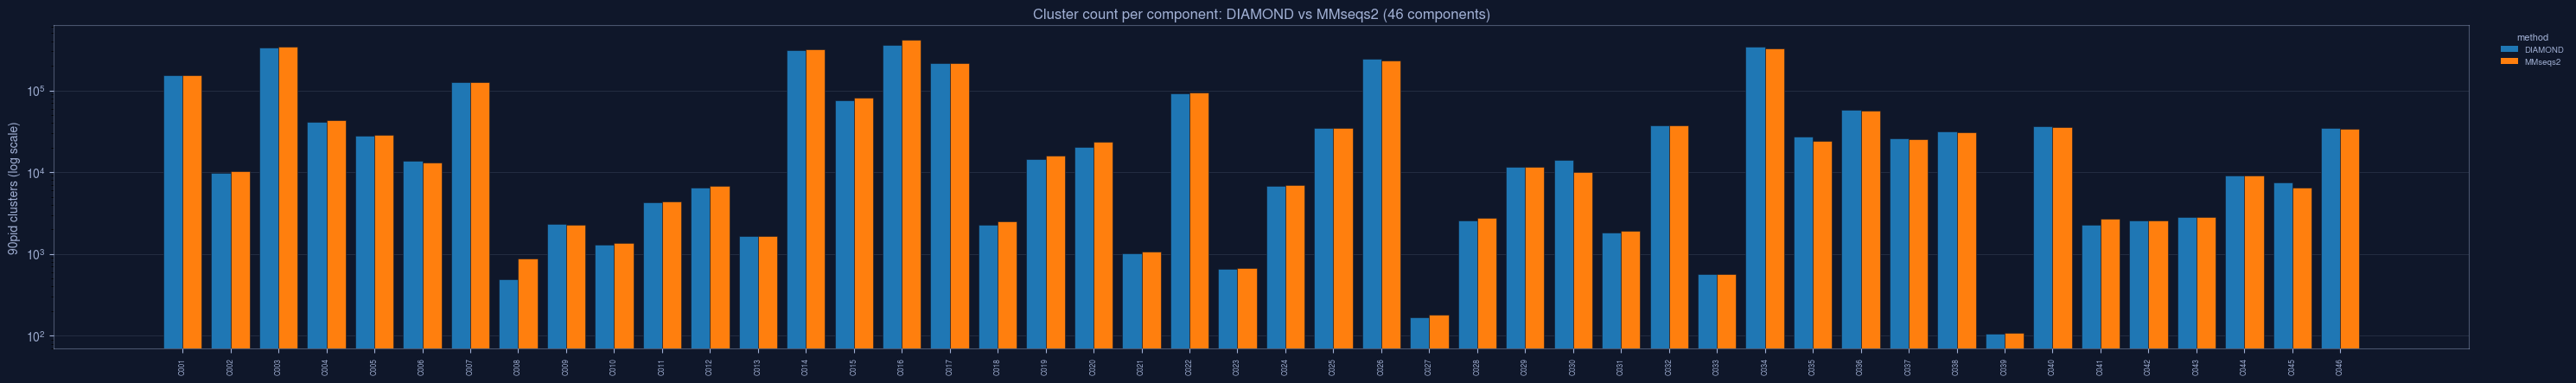

Saved cluster count bar plot to ./5_creating_logan_query/images/cluster_comparison/cluster_counts_by_component.png


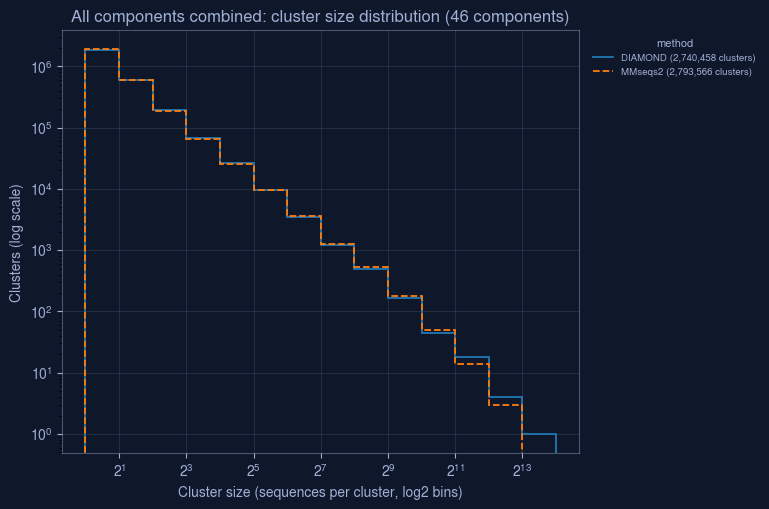

Saved pooled cluster size histogram to ./5_creating_logan_query/images/cluster_comparison/cluster_size_histogram_all_components.png


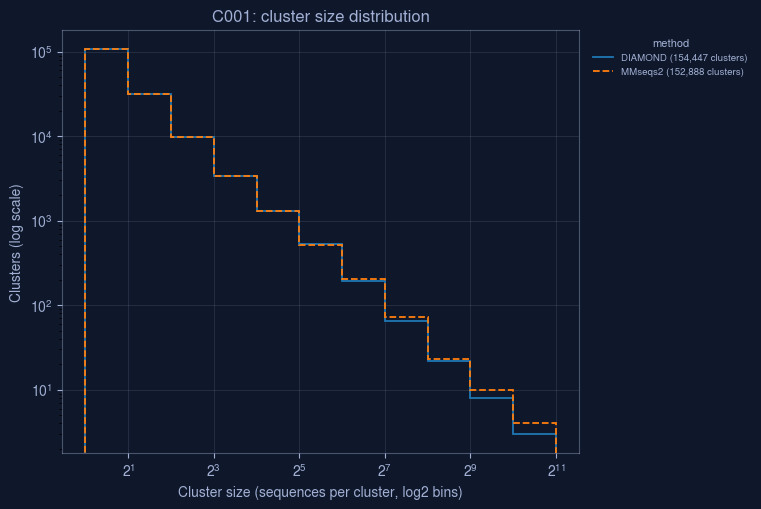

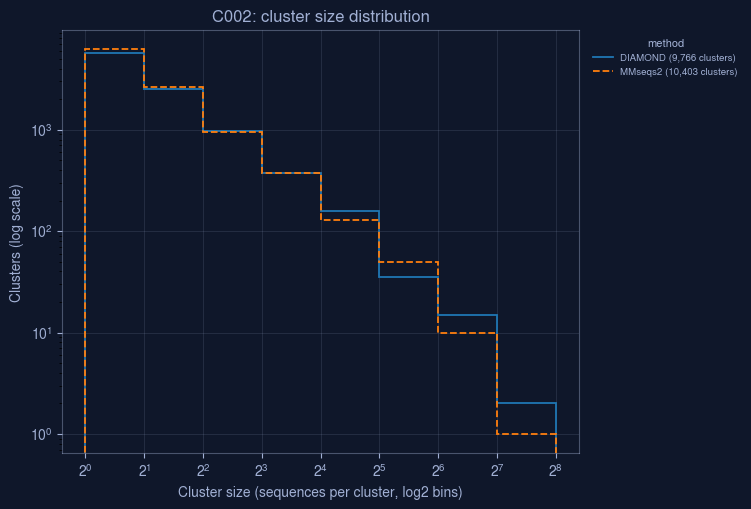

Plotted 46 / 46 components
Saved per-component cluster size histograms to ./5_creating_logan_query/images/cluster_comparison_per_component/


In [5]:
# ───────────── #
# SCRIPT SET UP #
# ───────────── #

import os
import glob
import math
from collections import Counter

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# ─── INPUT ─── #
DIAMOND_CLUSTERING_DIRECTORY = "./5_creating_logan_query/clustering_per_component" # petadex.v260701.clustering.{component_id}.tsv
"""
centroid    member (one row per member, centroid included)
ex.
NR223|21|230|C001    NR128125|83|292|C001
header format: petadex_id|hmm_target_start|hmm_target_end|component_id
"""

MMSEQS2_CLUSTERING_DIRECTORY = "./5_creating_logan_query/mmseqs2_clustering_per_component" # petadex.v260701.clustering.{component_id}_cluster.tsv
"""
centroid    member (one row per member, centroid included) -- same layout as the DIAMOND tsv
"""

# ─── OUTPUT ─── #
CLUSTER_COMPARISON_PLOT_DIR = "./5_creating_logan_query/images/cluster_comparison"
CLUSTER_COMPARISON_PER_COMPONENT_DIR = "./5_creating_logan_query/images/cluster_comparison_per_component" # {component_id}.png
os.makedirs(CLUSTER_COMPARISON_PLOT_DIR, exist_ok=True)
os.makedirs(CLUSTER_COMPARISON_PER_COMPONENT_DIR, exist_ok=True)

INLINE_SAMPLE_COUNT = 2  # number of components displayed inline; the rest are saved-only

# ─── PLOT STYLE (matches dataset_generation/4_hmm_creation.ipynb) ─── #
BACKGROUND_COLOR = "#0f172a"
TEXT_COLOR = "#a1b0d4"
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "Helvetica", "Nimbus Sans", "DejaVu Sans"]

# tab20 pairs each hue with a lighter shade of itself, so skip one swatch to
# get two clearly different hues (blue, orange) instead of blue/light blue
METHOD_COLOR = {
    "DIAMOND": plt.get_cmap("tab20").colors[0],
    "MMseqs2": plt.get_cmap("tab20").colors[2],
}
METHOD_LINESTYLE = {"DIAMOND": "-", "MMseqs2": "--"}  # dashed so identical histograms stay visible on top of each other

# ──────────────────────────────────────────── #
# LOAD CLUSTER SIZES PER METHOD AND COMPONENT  #
# ──────────────────────────────────────────── #

def load_clustering_directory(directory, suffix):
    """component_id -> Counter(centroid -> cluster size), sizes counting the centroid itself."""
    prefix = "petadex.v260701.clustering."
    sizes_by_component = {}
    for tsv_path in sorted(glob.glob(os.path.join(directory, f"{prefix}*{suffix}"))):
        component_id = os.path.basename(tsv_path)[len(prefix):-len(suffix)]
        sizes = Counter()
        with open(tsv_path) as infile:
            for line in infile:
                centroid, _member = line.rstrip("\n").split("\t")
                sizes[centroid] += 1
        sizes_by_component[component_id] = sizes
    return sizes_by_component


diamond_sizes = load_clustering_directory(DIAMOND_CLUSTERING_DIRECTORY, ".tsv")
mmseqs2_sizes = load_clustering_directory(MMSEQS2_CLUSTERING_DIRECTORY, "_cluster.tsv")

if not mmseqs2_sizes:
    raise FileNotFoundError(f"No MMseqs2 clustering tsvs found in {MMSEQS2_CLUSTERING_DIRECTORY} -- run section 2.3.1 first")

print(f"{len(diamond_sizes)} DIAMOND and {len(mmseqs2_sizes)} MMseqs2 clustering files loaded")

only_one_method = sorted(set(diamond_sizes) ^ set(mmseqs2_sizes))
if only_one_method:
    print(f"WARNING: {len(only_one_method)} component(s) clustered by only one method -- skipping: {', '.join(only_one_method)}")

component_ids = sorted(set(diamond_sizes) & set(mmseqs2_sizes))

# ─── SANITY CHECK: BOTH METHODS CLUSTERED THE SAME PRECLUSTER FASTAA ─── #
for component_id in component_ids:
    n_diamond = sum(diamond_sizes[component_id].values())
    n_mmseqs2 = sum(mmseqs2_sizes[component_id].values())
    if n_diamond != n_mmseqs2:
        print(f"WARNING: {component_id} has {n_diamond:,} DIAMOND members but {n_mmseqs2:,} MMseqs2 members")

# ──────────────────────────────── #
# PER-COMPONENT COMPARISON TABLE   #
# ──────────────────────────────── #

def summarize(sizes):
    """(sequences, clusters, singletons, largest cluster) for one Counter of cluster sizes."""
    values = sizes.values()
    return sum(values), len(sizes), sum(1 for size in values if size == 1), max(values, default=0)


columns = ["sequences", "diamond_clusters", "mmseqs2_clusters", "ratio", "diamond_singletons", "mmseqs2_singletons", "diamond_largest", "mmseqs2_largest"]

print()
print(f"{'component':<10}" + "".join(f"{column:>20}" for column in columns))
totals = Counter()
largest = Counter()
for component_id in component_ids:
    n_sequences, d_clusters, d_singletons, d_largest = summarize(diamond_sizes[component_id])
    _n_sequences, m_clusters, m_singletons, m_largest = summarize(mmseqs2_sizes[component_id])
    totals.update(sequences=n_sequences, diamond_clusters=d_clusters, mmseqs2_clusters=m_clusters,
                  diamond_singletons=d_singletons, mmseqs2_singletons=m_singletons)
    largest["diamond_largest"] = max(largest["diamond_largest"], d_largest)
    largest["mmseqs2_largest"] = max(largest["mmseqs2_largest"], m_largest)
    ratio = d_clusters / m_clusters if m_clusters else float("nan")
    print(f"{component_id:<10}{n_sequences:>20,}{d_clusters:>20,}{m_clusters:>20,}{ratio:>20.3f}"
          f"{d_singletons:>20,}{m_singletons:>20,}{d_largest:>20,}{m_largest:>20,}")

total_ratio = totals["diamond_clusters"] / totals["mmseqs2_clusters"] if totals["mmseqs2_clusters"] else float("nan")
print(f"{'total':<10}{totals['sequences']:>20,}{totals['diamond_clusters']:>20,}{totals['mmseqs2_clusters']:>20,}{total_ratio:>20.3f}"
      f"{totals['diamond_singletons']:>20,}{totals['mmseqs2_singletons']:>20,}{largest['diamond_largest']:>20,}{largest['mmseqs2_largest']:>20,}")
print("ratio = diamond_clusters / mmseqs2_clusters (> 1 means DIAMOND split sequences into more clusters)")

# ──────────────────────────────────────── #
# PLOT CLUSTER COUNTS PER COMPONENT        #
# ──────────────────────────────────────── #

def style_axes(ax):
    ax.tick_params(colors=TEXT_COLOR)
    for spine in ax.spines.values():
        spine.set_color(TEXT_COLOR)
        spine.set_alpha(0.4)
    ax.grid(True, axis="y", which="major", color=TEXT_COLOR, alpha=0.2, linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)


def add_method_legend(ax, handles):
    legend = ax.legend(
        handles=handles, title="method", loc="upper left",
        bbox_to_anchor=(1.01, 1.0), fontsize=7, title_fontsize=8,
        frameon=False, labelcolor=TEXT_COLOR,
    )
    legend.get_title().set_color(TEXT_COLOR)


def plot_cluster_counts(component_ids, out_path, show=True):
    """
    Grouped bar plot: one bar-group per component_id, one bar per clustering
    method -- same layout as 2.5's plot_qc_bar_group. Log-scaled y-axis since
    component cluster counts span several orders of magnitude.
    """
    methods = [("DIAMOND", diamond_sizes), ("MMseqs2", mmseqs2_sizes)]
    bar_width = 0.8 / len(methods)
    group_positions = list(range(len(component_ids)))

    fig, ax = plt.subplots(figsize=(max(8, len(component_ids) * 0.9), 5.5), facecolor=BACKGROUND_COLOR)
    ax.set_facecolor(BACKGROUND_COLOR)

    for method_idx, (method, sizes_by_component) in enumerate(methods):
        offsets = [pos + (method_idx - (len(methods) - 1) / 2) * bar_width for pos in group_positions]
        values = [len(sizes_by_component[component_id]) for component_id in component_ids]
        ax.bar(offsets, values, width=bar_width, color=METHOD_COLOR[method],
               edgecolor=BACKGROUND_COLOR, linewidth=0.4, zorder=3)

    ax.set_yscale("log")
    ax.set_xticks(group_positions)
    ax.set_xticklabels(component_ids, rotation=90, fontsize=6, color=TEXT_COLOR)

    ax.set_ylabel("90pid clusters (log scale)", color=TEXT_COLOR)
    ax.set_title(f"Cluster count per component: DIAMOND vs MMseqs2 ({len(component_ids)} components)", color=TEXT_COLOR)
    style_axes(ax)

    add_method_legend(ax, [Patch(facecolor=METHOD_COLOR[method], edgecolor="none", label=method) for method, _sizes in methods])

    fig.subplots_adjust(right=0.8, bottom=0.2)
    plt.savefig(out_path, facecolor=BACKGROUND_COLOR, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)


plot_cluster_counts(component_ids, os.path.join(CLUSTER_COMPARISON_PLOT_DIR, "cluster_counts_by_component.png"), show=True)
print(f"Saved cluster count bar plot to {CLUSTER_COMPARISON_PLOT_DIR}/cluster_counts_by_component.png")

# ──────────────────────────────────────── #
# PLOT CLUSTER SIZE HISTOGRAMS             #
# ──────────────────────────────────────── #

def plot_cluster_size_histogram(title, sizes_by_method, out_path, show=False):
    """
    Overlaid cluster-size histogram, one unfilled "step" distribution per
    clustering method (same style as 4_hmm_creation's plot_evalue_histogram).
    Bins double in width (1, 2-3, 4-7, ...) so singletons get their own bin
    -- if DIAMOND has inflated the cluster count, it shows up here as extra
    clusters in the smallest bins relative to MMseqs2.
    """
    max_size = max((max(sizes, default=1) for sizes in sizes_by_method.values()), default=1)
    n_bins = max(1, math.ceil(math.log2(max_size + 1)))
    bin_edges = [2 ** i for i in range(n_bins + 1)]

    fig, ax = plt.subplots(figsize=(9, 5.5), facecolor=BACKGROUND_COLOR)
    ax.set_facecolor(BACKGROUND_COLOR)

    legend_handles = []
    for method, sizes in sizes_by_method.items():
        if not sizes:
            continue
        color = METHOD_COLOR[method]
        linestyle = METHOD_LINESTYLE[method]
        ax.hist(sizes, bins=bin_edges, histtype="step", color=color, linestyle=linestyle, linewidth=1.3, zorder=3)
        legend_handles.append(Line2D([0], [0], color=color, linestyle=linestyle, lw=1.3, label=f"{method} ({len(sizes):,} clusters)"))

    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xlabel("Cluster size (sequences per cluster, log2 bins)", color=TEXT_COLOR)
    ax.set_ylabel("Clusters (log scale)", color=TEXT_COLOR)
    ax.set_title(title, color=TEXT_COLOR)
    style_axes(ax)
    ax.grid(True, axis="x", which="major", color=TEXT_COLOR, alpha=0.2, linewidth=0.5, zorder=0)

    add_method_legend(ax, legend_handles)

    fig.subplots_adjust(right=0.7)
    plt.savefig(out_path, facecolor=BACKGROUND_COLOR, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)


# ─── ALL COMPONENTS POOLED ─── #
pooled_sizes = {
    "DIAMOND": [size for component_id in component_ids for size in diamond_sizes[component_id].values()],
    "MMseqs2": [size for component_id in component_ids for size in mmseqs2_sizes[component_id].values()],
}
plot_cluster_size_histogram(
    f"All components combined: cluster size distribution ({len(component_ids)} components)",
    pooled_sizes,
    os.path.join(CLUSTER_COMPARISON_PLOT_DIR, "cluster_size_histogram_all_components.png"),
    show=True,
)
print(f"Saved pooled cluster size histogram to {CLUSTER_COMPARISON_PLOT_DIR}/cluster_size_histogram_all_components.png")

# ─── ONE HISTOGRAM PER COMPONENT (SAVE ALL, DISPLAY ONLY THE SAMPLE) ─── #
inline_sample_component_ids = set(component_ids[:INLINE_SAMPLE_COUNT])

n_plotted = 0
for component_id in component_ids:
    n_plotted += 1
    if n_plotted % 10 == 0:
        print(f"\rPlotted {n_plotted:,} / {len(component_ids):,} components", end="", flush=True)

    plot_cluster_size_histogram(
        f"{component_id}: cluster size distribution",
        {"DIAMOND": list(diamond_sizes[component_id].values()), "MMseqs2": list(mmseqs2_sizes[component_id].values())},
        os.path.join(CLUSTER_COMPARISON_PER_COMPONENT_DIR, f"{component_id}.png"),
        show=component_id in inline_sample_component_ids,
    )

print(f"\rPlotted {n_plotted:,} / {len(component_ids):,} components")
print(f"Saved per-component cluster size histograms to {CLUSTER_COMPARISON_PER_COMPONENT_DIR}/")

### 2.4. Create the Logan Query
---
This code block will extract the centroids from the clustering output files, take their amino acid sequences from the clustering input files and then create one large fastaa.

In [6]:
# ───────────── #
# SCRIPT SET UP #
# ───────────── #

import os
import glob

# ─── INPUT ─── #
PRECLUSTER_QUERY_DIRECTORY = "./5_creating_logan_query/precluster_per_component" # petadex-nr.v260701.precluster_logan_query.{component_id}.fastaa
"""
header format:
>petadex_id|hmm_target_start|hmm_target_end|component_id
ex.
>KAG5547207.1:KAI8553478.1|2|150|C003
"""

CLUSTERING_OUTPUT_DIRECTORY="./5_creating_logan_query/clustering_per_component"
"""
centroid    member
"""

# ─── OUTPUT ─── #
LOGAN_QUERY = "../s3/5_creating_logan_query/petadex.v260701.logan_query.fastaa"
"""
header format:
>petadex_id|hmm_target_start|hmm_target_end|component_id
ex.
>KAG5547207.1:KAI8553478.1|2|150|C003
"""

# ────────────────────── #
# RETRIEVE ALL CENTROIDS #
# ────────────────────── #

# ─── PARSE THROUGH ALL CLUSTERING FILES AND OBTAIN ALL CENTROID PETADEX_IDS AND COMPONENTS_IDS ─── #
# the header is unambiguous (petadex_id|hmm_target_start|hmm_target_end|component_id), so the
# full header string doubles as a unique key -- no need to track component_id separately here.

centroid_headers = set()
for tsv_path in sorted(glob.glob(os.path.join(CLUSTERING_OUTPUT_DIRECTORY, "petadex.v260701.clustering.*.tsv"))):
    with open(tsv_path) as infile:
        for line in infile:
            centroid, _member = line.rstrip("\n").split("\t")
            centroid_headers.add(centroid)

print(f"{len(centroid_headers):,} centroids found across {len(glob.glob(os.path.join(CLUSTERING_OUTPUT_DIRECTORY, '*.tsv')))} clustering files")

# ───────────────────────────── #
# CREATE THE LOGAN QUERY FASTAA #
# ───────────────────────────── #

# ─── PARSE THROUGH ALL COMPONENT FASTAAS AND GET HEADER AND SEQUENCE FOR ALL CENTROIDS ─── #

n_written = 0
current_header = None
current_is_centroid = False

# ─── CREATE THE LOGAN QUERY FILE ─── #
with open(LOGAN_QUERY, "w") as outfile:
    for fastaa_path in sorted(glob.glob(os.path.join(PRECLUSTER_QUERY_DIRECTORY, "*.fastaa"))):
        with open(fastaa_path) as infile:
            for line in infile:
                if line.startswith(">"):
                    current_header = line[1:].strip()
                    current_is_centroid = current_header in centroid_headers
                    if current_is_centroid:
                        outfile.write(line)
                    continue

                if current_is_centroid:
                    outfile.write(line)
                    n_written += 1

print(f"{n_written:,} centroid sequences written -> {LOGAN_QUERY}")

2,740,458 centroids found across 46 clustering files
2,740,458 centroid sequences written -> ../s3/5_creating_logan_query/petadex.v260701.logan_query.fastaa


### 2.5. Visualize the each quality control step
---
In this section, I will create a bar plot per component to show:
1. The count of unique accessions below the e-value cutoff per component after the initial NCBI nr DIAMOND search (DIAMOND_SIGNIFICANT_HITS).
2. The count of unique accessions below the e-value cutoff per component from the HMM search(PETADEX_PLASTICOME_NR_HMM_ANNOTATIONS).
3. The count of unique accessions that have a residue in each of the catalytic posisitions per component from the HMM search (PETADEX_PLASTICOME_NR_HMM_ANNOTATIONS).
4. The count of unique accessions that have the canonical residue in each of the catalytic positions per component from the HMM search
5. The count of 90pid centroids post DIAMOND clustering (LOGAN_QUERY).
6. The count of unique sequences that have 2+ catalytically complete domain hits (PETADEX_PLASTICOME_NR_HMM_ANNOTATIONS).
7. The count of unique sequences that have have only catalytically-incomplete HMM hits, but the hits complement each other on the catalytic residues (a has 1 and 2 but not 3, b has 3 but not 1 or 2).

7,825,107 DIAMOND significant hit records across 46 components
2,740,458 Logan query centroid records across 46 components
9,468,263 total annotation rows, 9,465,770 below E-value cutoff 1e-05, 7,562,397 unique accessions
Reduced to per-component QC counts across 46 components

component     DIAMOND significant hits        HMM significant hits           Catalytic present         Catalytic canonical       Logan 90pid centroids         2+ distinct domainsComplementary incomplete hits
C001                           653,033                     406,030                     361,700                     308,888                     154,447                         338                          21
C002                            28,185                      28,155                      26,865                      26,530                       9,766                          23                           5
C003                           905,480                     904,120                     818,795     

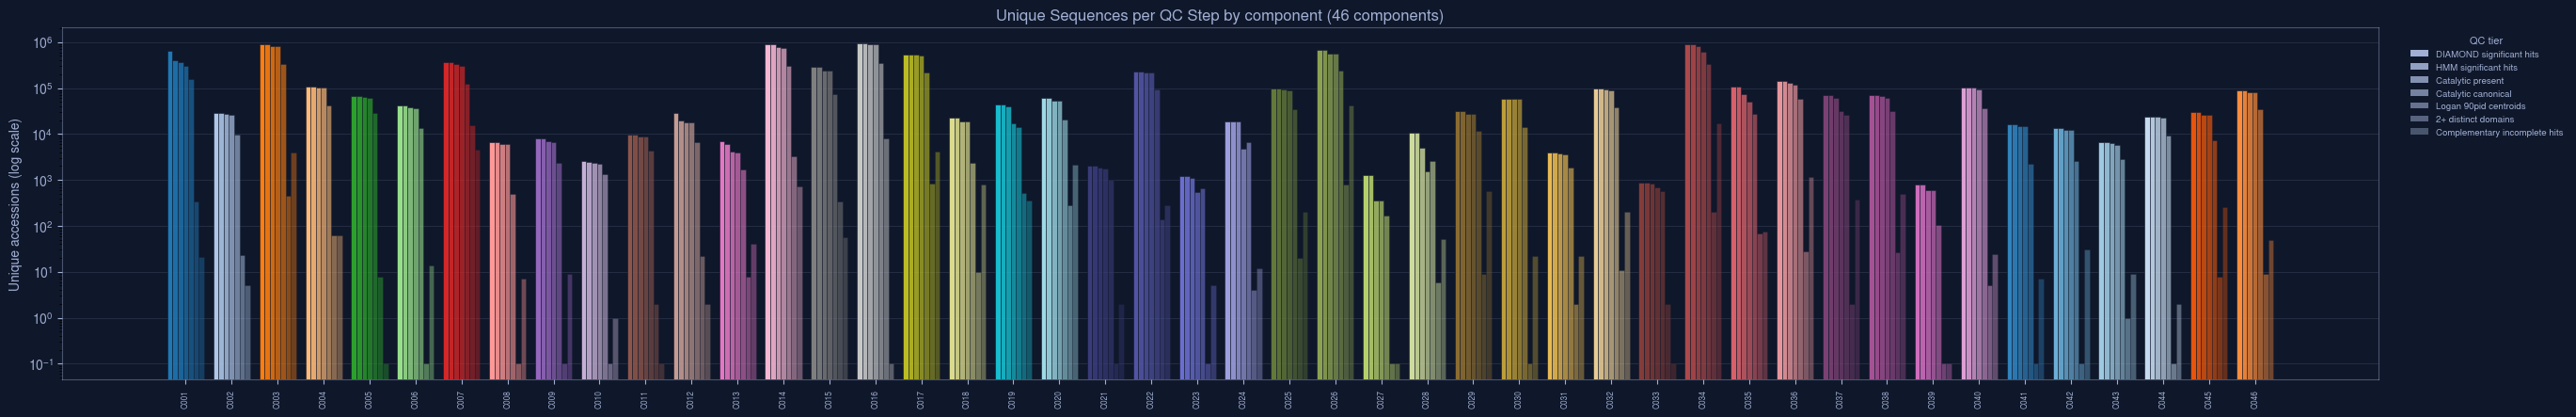

Saved QC funnel bar plot to ./5_creating_logan_query/images/qc_bar_plots/qc_summary.png


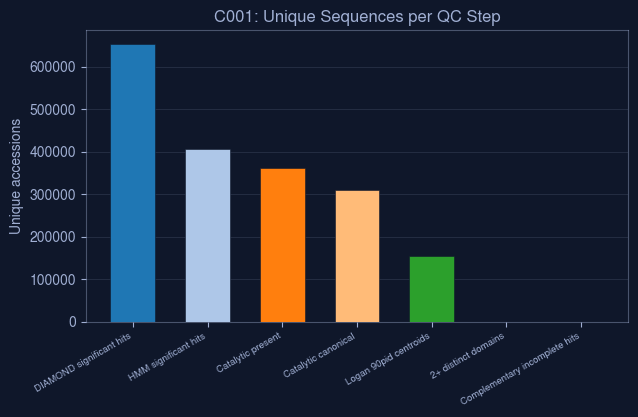

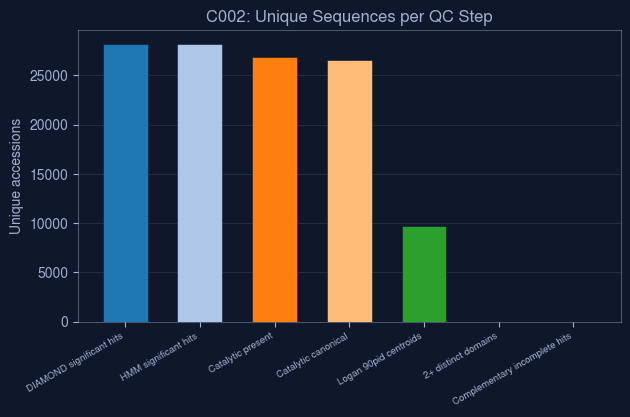

Plotted 46 / 46 components
Saved per-component QC bar plots to ./5_creating_logan_query/images/qc_bar_plots_per_component/


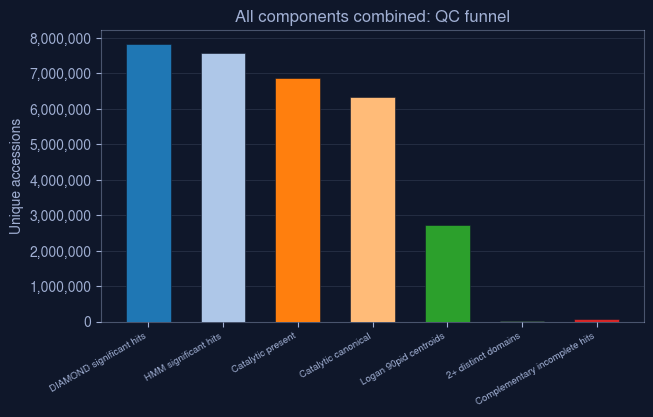

Saved all-components-combined QC bar plot to ./5_creating_logan_query/images/qc_bar_plots/qc_totals_summary.png


In [7]:
import csv
import os
import re
from collections import Counter

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

# ───────────── #
# SCRIPT SET UP #
# ───────────── #

# ─── INPUT ─── #
DIAMOND_SIGNIFICANT_HITS = "../s3/2_nr_search/petadex-nr.v260701.significant-hits.fastaa"
"""
>WP_305403363.1|7.24e-11|23.5|73.6|PL181|C034 # last field of the header is component_id by rsplit("|", 6)
"""

PETADEX_PLASTICOME_NR_HMM_ANNOTATIONS = "../s3/5_creating_logan_query/petadex-nr.v260701.catalytic_domain_annotations.csv"
"""
column format:
petadex_id,component_id,hmm_name,hmm_evalue,hmm_target_start,hmm_target_end,complete_catalytic_hit,catalytic_site_identities
ex.
KAG5547207.1:KAI8553478.1,C001,C001-1.hmm,3.21e-19,2,150,TRUE,S130(S165):D183(E203):H213(H290)
an accession/id can appear on multiple rows if it has multiple significant hits
"""

LOGAN_QUERY = "../s3/5_creating_logan_query/petadex.v260701.logan_query.fastaa"
"""
header format:
>petadex_id|hmm_target_start|hmm_target_end|component_id
ex.
>KAG5547207.1:KAI8553478.1|2|150|C003
"""

# ─── OUTPUT ─── #
QC_BAR_PLOT_DIR = "./5_creating_logan_query/images/qc_bar_plots"
os.makedirs(QC_BAR_PLOT_DIR, exist_ok=True)

EVALUE_CUTOFF = 1.0e-5  # matches section 2.2's cutoff; CSV is already pre-filtered to this, so this is defensive

# ─── PLOT STYLE (matches dataset_generation/4_hmm_creation.ipynb) ─── #
BACKGROUND_COLOR = "#0f172a"
TEXT_COLOR = "#a1b0d4"
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "Helvetica", "Nimbus Sans", "DejaVu Sans"]

QC_METRICS = [
    ("diamond_significant", "DIAMOND significant hits"),
    ("hmm_significant", "HMM significant hits"),
    ("catalytic_present", "Catalytic present"),
    ("catalytic_canonical", "Catalytic canonical"),
    ("logan_centroids", "Logan 90pid centroids"),
    ("multi_domain_complete", "2+ distinct domains"),
    ("complementary_hits", "Complementary incomplete hits"),
]


def build_categorical_palette(n):
    # tab20 + tab20b + tab20c gives 60 visually distinct swatches, matplotlib's
    # standard trick for coloring many categories
    swatches = list(plt.get_cmap("tab20").colors) + list(plt.get_cmap("tab20b").colors) + list(plt.get_cmap("tab20c").colors)
    return [swatches[i % len(swatches)] for i in range(n)]


# ──────────────────────────────────────────────────── #
# METRICS 1 & 5: COUNT FASTA RECORDS PER COMPONENT_ID   #
# ──────────────────────────────────────────────────── #

def count_records_by_component(fastaa_path):
    """component_id is always the header's last '|'-field in every fastaa this notebook writes."""
    counts = Counter()
    with open(fastaa_path) as infile:
        for line in infile:
            if line.startswith(">"):
                component_id = line[1:].strip().rsplit("|", 1)[-1]
                counts[component_id] += 1
    return counts


diamond_counts = count_records_by_component(DIAMOND_SIGNIFICANT_HITS)
logan_counts = count_records_by_component(LOGAN_QUERY)

print(f"{sum(diamond_counts.values()):,} DIAMOND significant hit records across {len(diamond_counts)} components")
print(f"{sum(logan_counts.values()):,} Logan query centroid records across {len(logan_counts)} components")

# ──────────────────────────────────────────────────────────────── #
# METRICS 2/3/4/6/7: SINGLE PASS OVER THE HMM ANNOTATIONS CSV       #
# ──────────────────────────────────────────────────────────────── #
# site token format "{aa_spec}{col}({found_char}{pos})", e.g. "S130(S165)" or
# a gapped site "S130(-NA)" -- see hmmsearch-260823.parse_output.py:453-460

SITE_TOKEN_RE = re.compile(r"^([A-Za-z/]+)(\d+)\((-|[A-Za-z])(NA|\d+)\)$")


def site_is_canonical(aa_spec, found_char):
    """Mirrors parse_output.py's PRESENT (canonical) vs MISMATCH/ABSENT per-site classification."""
    if found_char == "-":
        return False
    accepted = {a.strip().upper() for a in aa_spec.split("/")}
    return found_char.upper() in accepted


def count_distinct_ranges(ranges):
    """
    Merges overlapping (hmm_target_start, hmm_target_end) ranges (sharing >=1
    residue) and returns how many non-overlapping regions remain -- two
    complete hits covering the same physical region (e.g. one sub-HMM's
    domain nested inside another's, as seen with C014.hmm/C014-2.hmm on the
    same accession) count as a single domain, not two.
    """
    if not ranges:
        return 0
    sorted_ranges = sorted(ranges)
    merged_count = 1
    current_end = sorted_ranges[0][1]
    for start, end in sorted_ranges[1:]:
        if start > current_end:
            merged_count += 1
            current_end = end
        else:
            current_end = max(current_end, end)
    return merged_count


# petadex_id -> component_id, complete/incomplete hit counts, and per-site coverage
by_petadex_id = {}

n_rows = 0
n_significant_rows = 0
with open(PETADEX_PLASTICOME_NR_HMM_ANNOTATIONS, newline="") as infile:
    for row in csv.DictReader(infile):
        n_rows += 1
        if float(row["hmm_evalue"]) >= EVALUE_CUTOFF:
            continue
        n_significant_rows += 1

        petadex_id = row["petadex_id"]
        entry = by_petadex_id.get(petadex_id)
        if entry is None:
            entry = {
                "component_id": row["component_id"],
                "n_complete": 0,
                "n_incomplete": 0,
                "row_canonical": False,
                "covered": set(),   # site columns with a non-gap residue, across all this id's hits
                "all_cols": set(),  # every site column mentioned across all this id's hits
                "complete_ranges": [],  # (hmm_target_start, hmm_target_end) for each complete hit
            }
            by_petadex_id[petadex_id] = entry

        is_complete = row["complete_catalytic_hit"] == "TRUE"
        if is_complete:
            entry["n_complete"] += 1
            entry["complete_ranges"].append((int(row["hmm_target_start"]), int(row["hmm_target_end"])))
        else:
            entry["n_incomplete"] += 1

        row_all_canonical = True
        for token in row["catalytic_site_identities"].split(":"):
            match = SITE_TOKEN_RE.match(token)
            if not match:
                continue
            aa_spec, col, found_char, _pos = match.groups()
            entry["all_cols"].add(col)
            if found_char != "-":
                entry["covered"].add(col)
            if not site_is_canonical(aa_spec, found_char):
                row_all_canonical = False

        if row_all_canonical:
            entry["row_canonical"] = True

print(f"{n_rows:,} total annotation rows, {n_significant_rows:,} below E-value cutoff {EVALUE_CUTOFF}, {len(by_petadex_id):,} unique accessions")

# ─── REDUCE PER-ACCESSION STATE TO PER-COMPONENT COUNTS ─── #

hmm_significant_counts = Counter()
catalytic_present_counts = Counter()
catalytic_canonical_counts = Counter()
multi_domain_counts = Counter()
complementary_counts = Counter()

for petadex_id, entry in by_petadex_id.items():
    component_id = entry["component_id"]
    hmm_significant_counts[component_id] += 1

    if entry["n_complete"] > 0:
        catalytic_present_counts[component_id] += 1
    if entry["row_canonical"]:
        catalytic_canonical_counts[component_id] += 1
    if count_distinct_ranges(entry["complete_ranges"]) >= 2:
        multi_domain_counts[component_id] += 1
    # complementary: never individually complete, but >=2 incomplete hits whose
    # covered sites union to the full site set between them (e.g. hit a has
    # sites 1&2, hit b has site 3 -- neither alone is complete, together they are)
    if entry["n_complete"] == 0 and entry["n_incomplete"] >= 2 and entry["all_cols"] and entry["covered"] == entry["all_cols"]:
        complementary_counts[component_id] += 1

print(f"Reduced to per-component QC counts across {len(hmm_significant_counts)} components")

# ──────────────────────────────── #
# ASSEMBLE PER-COMPONENT QC TABLE  #
# ──────────────────────────────── #

metric_counters = {
    "diamond_significant": diamond_counts,
    "hmm_significant": hmm_significant_counts,
    "catalytic_present": catalytic_present_counts,
    "catalytic_canonical": catalytic_canonical_counts,
    "logan_centroids": logan_counts,
    "multi_domain_complete": multi_domain_counts,
    "complementary_hits": complementary_counts,
}

all_component_ids = sorted(set().union(*(set(counter) for counter in metric_counters.values())))

print()
print(f"{'component':<10}" + "".join(f"{label:>28}" for _field, label in QC_METRICS))
totals = Counter()
for component_id in all_component_ids:
    row_cells = []
    for field, _label in QC_METRICS:
        value = metric_counters[field][component_id]
        totals[field] += value
        row_cells.append(f"{value:>28,}")
    print(f"{component_id:<10}" + "".join(row_cells))
print(f"{'total':<10}" + "".join(f"{totals[field]:>28,}" for field, _label in QC_METRICS))

# ─────────────────────── #
# PLOT THE QC FUNNEL BARS #
# ─────────────────────── #

component_color = dict(zip(all_component_ids, build_categorical_palette(len(all_component_ids))))


def plot_qc_bar_group(component_ids, out_path, show=True):
    """
    Grouped bar plot: one bar-group per component_id (colored consistently
    across tiers via component_color), one alpha-shaded bar per QC_METRICS
    tier within each group -- same layout as 4_hmm_creation.ipynb's
    plot_bar_group, with component_id taking the place of its (run_label,
    iteration_name) variant axis. Log-scaled y-axis since the funnel spans
    ~3 orders of magnitude (DIAMOND hits down to complementary hits), unlike
    4_hmm_creation's same-order-of-magnitude metrics.
    """
    n_metrics = len(QC_METRICS)
    bar_width = 0.8 / n_metrics
    group_positions = list(range(len(component_ids)))

    fig, ax = plt.subplots(figsize=(max(8, len(component_ids) * 0.9), 5.5), facecolor=BACKGROUND_COLOR)
    ax.set_facecolor(BACKGROUND_COLOR)

    for metric_idx, (field, _label) in enumerate(QC_METRICS):
        offsets = [pos + (metric_idx - (n_metrics - 1) / 2) * bar_width for pos in group_positions]
        values = [metric_counters[field][component_id] for component_id in component_ids]
        # log scale can't render a true zero -- floor at 0.1 so an empty tier still shows as a hairline
        plot_values = [v if v > 0 else 0.1 for v in values]
        colors = [component_color[component_id] for component_id in component_ids]
        alpha = 1.0 - 0.1 * metric_idx
        ax.bar(offsets, plot_values, width=bar_width, color=colors, alpha=alpha,
               edgecolor=BACKGROUND_COLOR, linewidth=0.4, zorder=3)

    ax.set_yscale("log")
    ax.set_xticks(group_positions)
    ax.set_xticklabels(component_ids, rotation=90, fontsize=6, color=TEXT_COLOR)

    ax.set_ylabel("Unique accessions (log scale)", color=TEXT_COLOR)
    ax.set_title(f"Unique Sequences per QC Step by component ({len(component_ids)} components)", color=TEXT_COLOR)

    ax.tick_params(colors=TEXT_COLOR)
    for spine in ax.spines.values():
        spine.set_color(TEXT_COLOR)
        spine.set_alpha(0.4)
    ax.grid(True, axis="y", which="major", color=TEXT_COLOR, alpha=0.2, linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)

    tier_legend_handles = [
        Patch(facecolor=TEXT_COLOR, edgecolor="none", alpha=1.0 - 0.1 * i, label=label)
        for i, (_field, label) in enumerate(QC_METRICS)
    ]
    tier_legend = ax.legend(
        handles=tier_legend_handles, title="QC tier", loc="upper left",
        bbox_to_anchor=(1.01, 1.0), fontsize=7, title_fontsize=8,
        frameon=False, labelcolor=TEXT_COLOR,
    )
    tier_legend.get_title().set_color(TEXT_COLOR)

    fig.subplots_adjust(right=0.72, bottom=0.2)
    plt.savefig(out_path, facecolor=BACKGROUND_COLOR, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)


plot_qc_bar_group(all_component_ids, os.path.join(QC_BAR_PLOT_DIR, "qc_summary.png"), show=True)
print(f"Saved QC funnel bar plot to {QC_BAR_PLOT_DIR}/qc_summary.png")

# ──────────────────────────────────────── #
# ONE BAR PLOT PER COMPONENT (SAME GROUPS) #
# ──────────────────────────────────────── #

QC_PER_COMPONENT_DIR = "./5_creating_logan_query/images/qc_bar_plots_per_component"
os.makedirs(QC_PER_COMPONENT_DIR, exist_ok=True)

INLINE_SAMPLE_COUNT = 2  # number of components displayed inline; the rest are saved-only

# one consistent hue per QC_METRICS tier, shared across every component's plot
# (unlike the combined plot above, only one component is shown per image here,
# so color is free to encode the metric instead of the component)
metric_color = dict(zip((field for field, _label in QC_METRICS), build_categorical_palette(len(QC_METRICS))))

inline_sample_component_ids = set(all_component_ids[:INLINE_SAMPLE_COUNT])


def plot_component_bars(component_id, out_path, show=False):
    """
    Single-component funnel bar plot: one bar per QC_METRICS tier (the same 7
    groups shown together in the combined plot above), colored by metric_color
    so a given tier is always the same color across every component's image.
    Linear y-axis (unlike the combined plot).
    """
    labels = [label for _field, label in QC_METRICS]
    values = [metric_counters[field][component_id] for field, _label in QC_METRICS]
    colors = [metric_color[field] for field, _label in QC_METRICS]
    positions = list(range(len(QC_METRICS)))

    fig, ax = plt.subplots(figsize=(7, 5.5), facecolor=BACKGROUND_COLOR)
    ax.set_facecolor(BACKGROUND_COLOR)

    ax.bar(positions, values, width=0.6, color=colors,
           edgecolor=BACKGROUND_COLOR, linewidth=0.4, zorder=3)

    ax.set_xticks(positions)
    ax.set_xticklabels(labels, rotation=30, ha="right", fontsize=7, color=TEXT_COLOR)

    ax.set_ylabel("Unique accessions", color=TEXT_COLOR)
    ax.set_title(f"{component_id}: Unique Sequences per QC Step", color=TEXT_COLOR)

    ax.tick_params(colors=TEXT_COLOR)
    for spine in ax.spines.values():
        spine.set_color(TEXT_COLOR)
        spine.set_alpha(0.4)
    ax.grid(True, axis="y", which="major", color=TEXT_COLOR, alpha=0.2, linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)

    fig.subplots_adjust(bottom=0.35)
    plt.savefig(out_path, facecolor=BACKGROUND_COLOR, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)


n_plotted = 0
for component_id in all_component_ids:
    n_plotted += 1
    if n_plotted % 10 == 0:
        print(f"\rPlotted {n_plotted:,} / {len(all_component_ids):,} components", end="", flush=True)

    show = component_id in inline_sample_component_ids
    plot_component_bars(component_id, os.path.join(QC_PER_COMPONENT_DIR, f"{component_id}.png"), show=show)

print(f"\rPlotted {n_plotted:,} / {len(all_component_ids):,} components")
print(f"Saved per-component QC bar plots to {QC_PER_COMPONENT_DIR}/")

# ──────────────────────────────────────────────────── #
# SUMMARY PLOT: EVERY COMPONENT COMBINED, PER CATEGORY  #
# ──────────────────────────────────────────────────── #

def plot_totals_bars(totals, out_path, show=True):
    """
    Whole-project funnel bar plot: one bar per QC_METRICS category, each the
    sum of that category's counts across all 46 components (the `totals`
    Counter accumulated while printing the per-component summary table
    above). Collapses the per-component dimension entirely -- unlike the
    combined plot (components x categories) and the per-component plots
    (one funnel per component), this is the single whole-pipeline funnel.
    Colored with the same metric_color mapping as the per-component plots.
    """
    labels = [label for _field, label in QC_METRICS]
    values = [totals[field] for field, _label in QC_METRICS]
    colors = [metric_color[field] for field, _label in QC_METRICS]
    positions = list(range(len(QC_METRICS)))

    fig, ax = plt.subplots(figsize=(7, 5.5), facecolor=BACKGROUND_COLOR)
    ax.set_facecolor(BACKGROUND_COLOR)

    ax.bar(positions, values, width=0.6, color=colors,
           edgecolor=BACKGROUND_COLOR, linewidth=0.4, zorder=3)

    ax.set_xticks(positions)
    ax.set_xticklabels(labels, rotation=30, ha="right", fontsize=7, color=TEXT_COLOR)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _pos: f"{value:,.0f}"))

    ax.set_ylabel("Unique accessions", color=TEXT_COLOR)
    ax.set_title("All components combined: QC funnel", color=TEXT_COLOR)

    ax.tick_params(colors=TEXT_COLOR)
    for spine in ax.spines.values():
        spine.set_color(TEXT_COLOR)
        spine.set_alpha(0.4)
    ax.grid(True, axis="y", which="major", color=TEXT_COLOR, alpha=0.2, linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)

    fig.subplots_adjust(bottom=0.35)
    plt.savefig(out_path, facecolor=BACKGROUND_COLOR, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)


plot_totals_bars(totals, os.path.join(QC_BAR_PLOT_DIR, "qc_totals_summary.png"), show=True)
print(f"Saved all-components-combined QC bar plot to {QC_BAR_PLOT_DIR}/qc_totals_summary.png")
